In [1]:
# Dimensionality Reduction is a technique in machine learning used to reduce the number of features or variables in a dataset while preserving the important information. 
# It helps simplify complex datasets, reduce computational time and improve data visualization. 
# It is especially useful when datasets contain a large number of features.

# Principal Component Analysis (PCA) is an unsupervised machine learning technique used for dimensionality reduction. 
# It transforms a dataset containing multiple correlated features into a smaller set of new variables called Principal Components. 
# These components are formed in such a way that they retain the maximum possible variance (information) from the original data.

# PCA works by first standardizing the dataset so that all features have a common scale. 
# It then calculates the covariance matrix and identifies eigenvalues and eigenvectors to determine the most important directions of variation in the data. 
# The principal components are selected according to the amount of variance they preserve.

# PCA is widely used in image processing, data visualization, pattern recognition and noise reduction. 
# Its main advantages are reduced data complexity, faster computation and removal of redundant information. 
# However, some information may be lost during dimensionality reduction, and the resulting components may be difficult to interpret.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [3]:
# Generate Chess Dataset
np.random.seed(42)
n = 1000
df = pd.DataFrame({
    'Elo_Rating': np.random.randint(2400, 2880, n),
    'Rapid_Rating': np.random.randint(2300, 2850, n),
    'Blitz_Rating': np.random.randint(2300, 2900, n),
    'Age': np.random.randint(16, 48, n),
    'Wins': np.random.randint(0, 15, n),
    'Draws': np.random.randint(2, 20, n),
    'Losses': np.random.randint(0, 10, n)
})
df['Total_Games'] = df['Wins'] + df['Draws'] + df['Losses']
df['Win_Ratio'] = df['Wins'] / df['Total_Games']

In [4]:
# Create Target Labels (3 Player Tiers)
y = np.where((df.Elo_Rating >= 2760) & (df.Win_Ratio >= 0.35), 2,
    np.where((df.Elo_Rating >= 2650) & (df.Win_Ratio >= 0.20), 1, 0))

In [5]:
# Standardize Features
X = StandardScaler().fit_transform(df)

In [6]:
# Apply PCA (9 Features to 2 Components)
X_pca = PCA(n_components=2).fit_transform(X)

In [7]:
# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
# Train KNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred) * 100)

Accuracy: 59.5


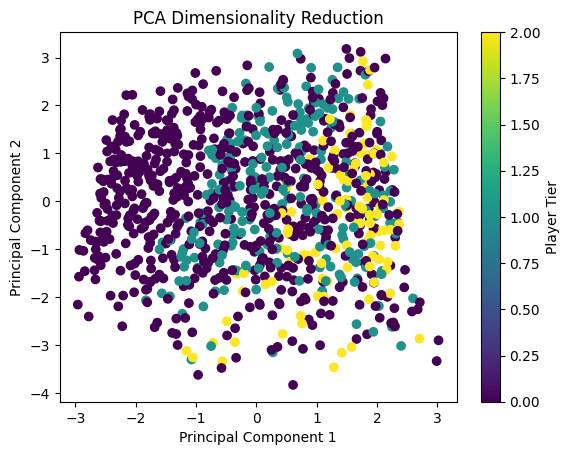

In [9]:
# Visualize PCA
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Dimensionality Reduction")
plt.colorbar(scatter, label="Player Tier")
plt.show()